# ゲート繰り返しと Pauli twirling の比較


In [1]:
from pathlib import Path
from IPython.display import display, Image

from repeated_gate_pauli_twirl_comparison import (
    DEFAULT_INPUT,
    DEFAULT_OUTPUT,
    compare,
    save_comparison,
)

REPETITIONS = (1, 3, 5, 10)
# "22245": 最小離調を探索したHughes波、"21700": 探索前の波形。
# 数値は100 µsへ短縮する前の最小離調に対応します。
# いずれも同じ波形の振幅校正前後を比較します。
HUGHES_REFERENCE = "22245"
INPUT_DIR = DEFAULT_INPUT
OUTPUT_DIR = DEFAULT_OUTPUT / f"hughes_{HUGHES_REFERENCE}"


In [2]:
# 保存済みの4条件について、twirling前後の繰り返し誤差を計算。
table, diagnostics, matrices = compare(
    input_dir=INPUT_DIR,
    hughes_reference=HUGHES_REFERENCE,
    repetitions=REPETITIONS,
)

comparison = table.pivot(
    index=["condition", "mode", "n"],
    columns="model",
    values="average_infidelity_percent",
).reset_index()
comparison.columns.name = None
comparison["full_minus_twirled_percentage_points"] = (
    comparison["full"] - comparison["twirled"]
)
print("full / twirled: 平均ゲート infidelity (%)")
display(comparison)


full / twirled: 平均ゲート infidelity (%)


,condition,mode,n,full,twirled,full_minus_twirled_percentage_points
0,Calibrated Hughes,error_only,1,0.518995,0.518995,0.000000
1,Calibrated Hughes,error_only,3,1.540674,1.540716,-0.000042
2,Calibrated Hughes,error_only,5,2.541017,2.541155,-0.000139
3,Calibrated Hughes,error_only,10,4.951663,4.952276,-0.000613
4,Calibrated Hughes,physical_gate,1,0.518995,0.518995,0.000000
5,Calibrated Hughes,physical_gate,3,1.540684,1.540716,-0.000033
6,Calibrated Hughes,physical_gate,5,2.541043,2.541155,-0.000112
7,Calibrated Hughes,physical_gate,10,4.951767,4.952276,-0.000509
8,Calibrated rectangular,error_only,1,0.936595,0.936595,0.000000
9,Calibrated rectangular,error_only,3,2.759835,2.766988,-0.007153


## グラフとファイル保存

各パネルで **full＝実線・○、twirled＝破線・□** を重ねます。上段は誤差チャネルの累乗、下段は実ゲートの繰り返しです。以下のセルでCSV・PNG・単発PTM・診断メタデータを保存します。


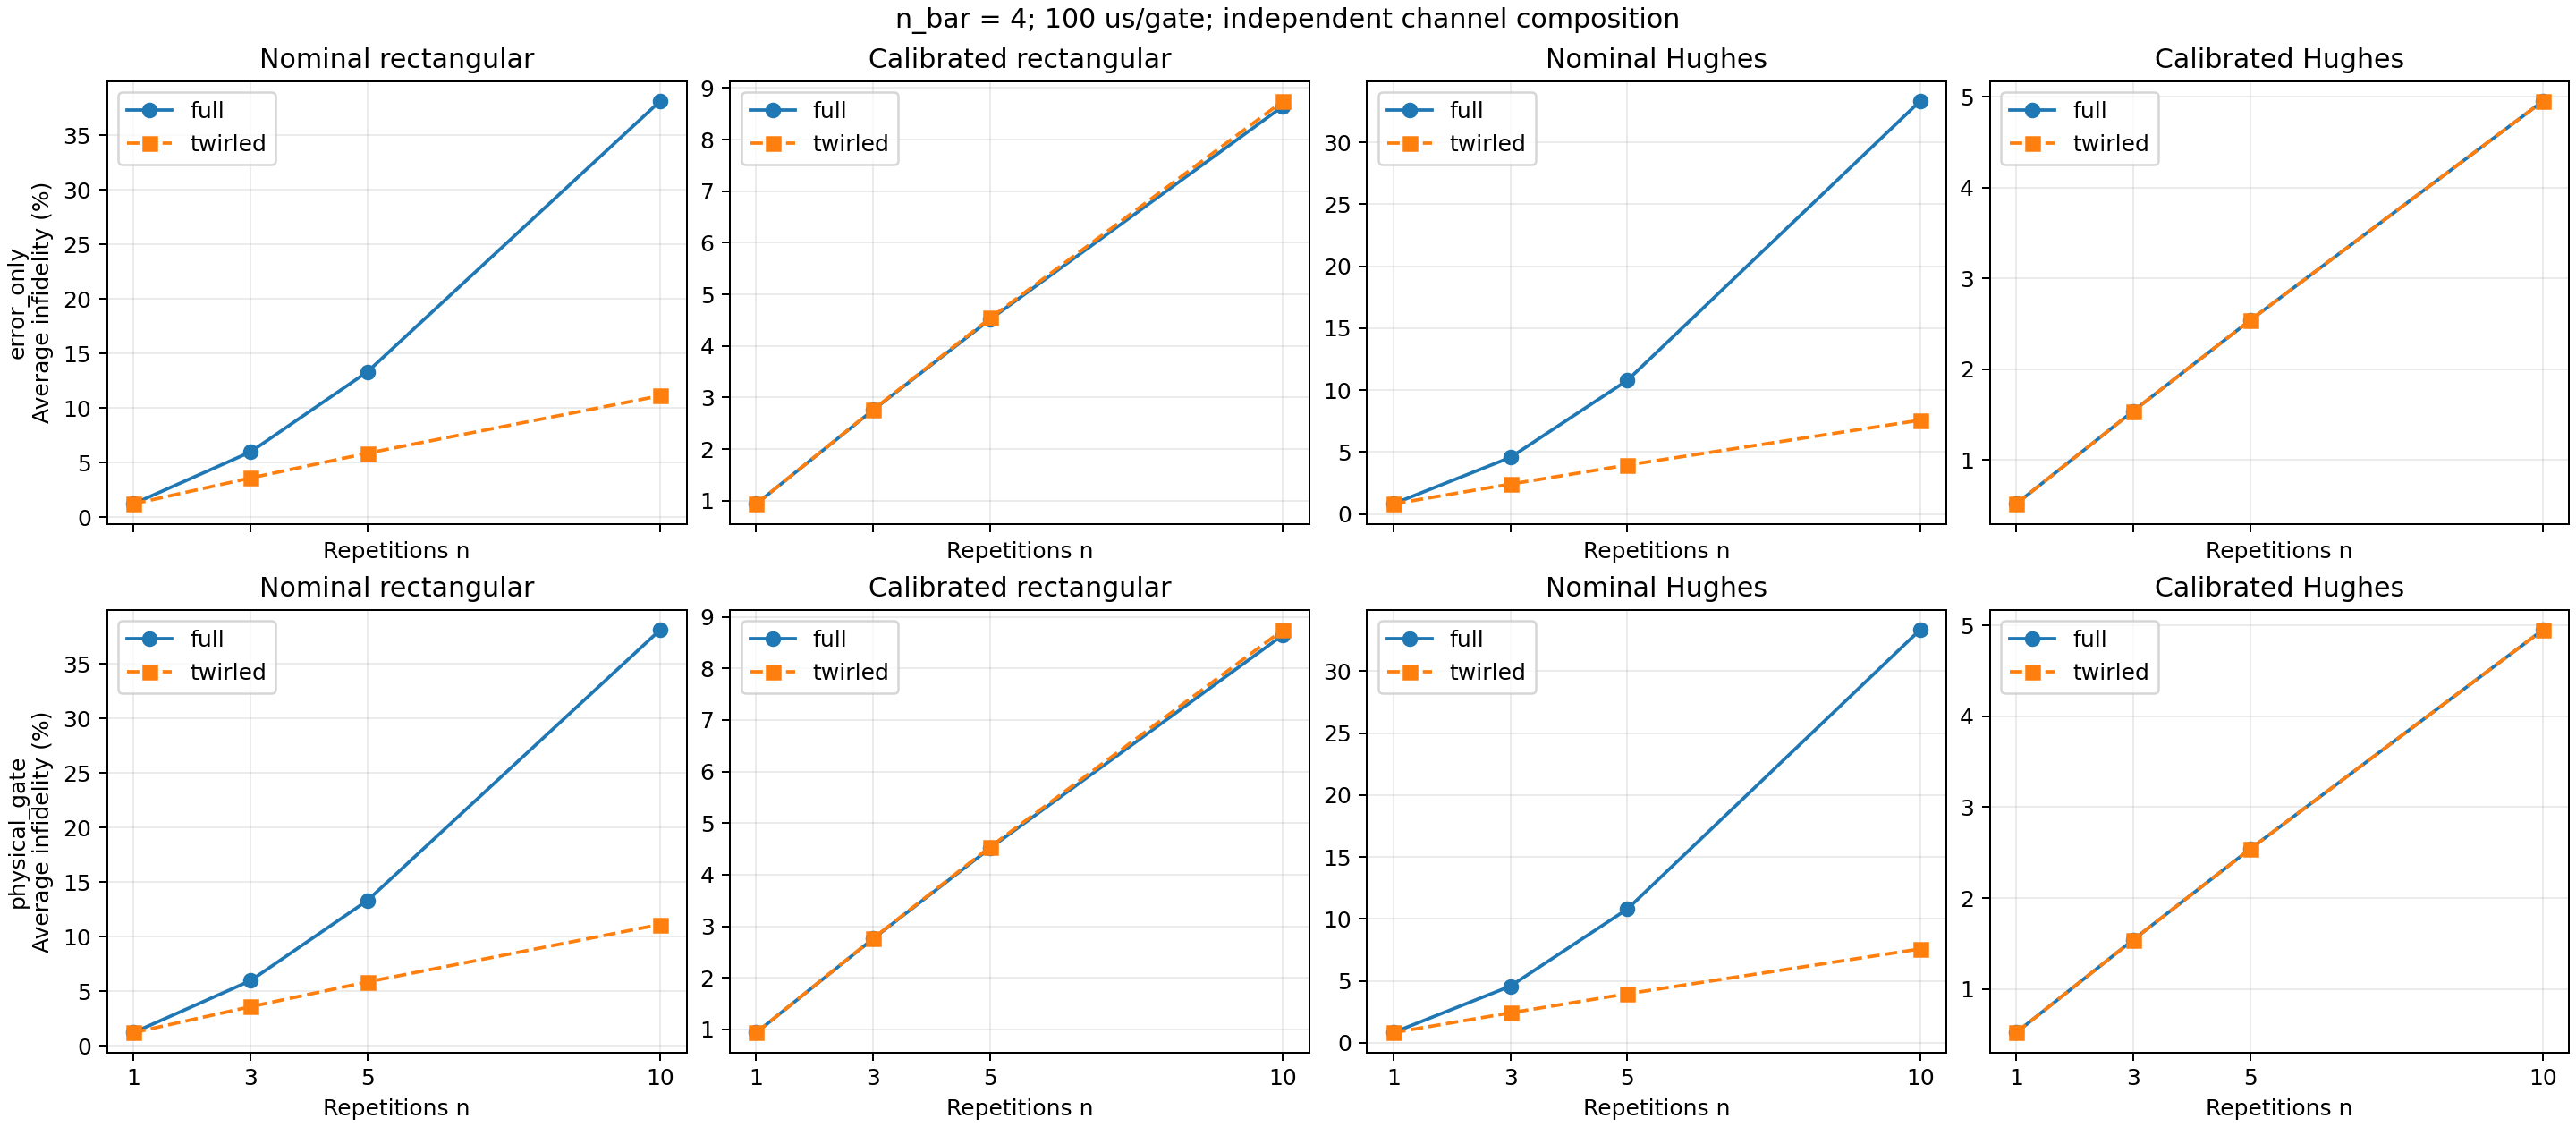

保存先: /workspace/results/repeated_gate_pauli_twirl/hughes_22245


In [3]:
save_comparison(
    table=table,
    diagnostics=diagnostics,
    matrices=matrices,
    output_dir=OUTPUT_DIR,
    hughes_reference=HUGHES_REFERENCE,
)
display(Image(filename=str(OUTPUT_DIR / "repeated_infidelity.png")))
print(f"保存先: {OUTPUT_DIR}")


In [4]:
import pandas as pd

display(pd.DataFrame(diagnostics))


,condition,source,amplitude_scale,projection_chi_frobenius_change,projection_status,chi_trace_error,choi_hermiticity_error,choi_min_eigenvalue,choi_tp_frobenius_error,cptp_within_tolerance
0,Nominal rectangular,/workspace/results/matched_pulse_calibration_s...,1.000000,8.505607e-16,"{'iterations': 1, 'min_choi_eigenvalue': 2.147...",0.000000e+00,4.300286e-16,2.147731e-07,3.386293e-16,True
1,Calibrated rectangular,/workspace/results/matched_pulse_calibration_s...,1.049773,5.004951e-16,"{'iterations': 1, 'min_choi_eigenvalue': 2.160...",1.710569e-49,7.022017e-16,2.160613e-07,4.299898e-16,True
2,Nominal Hughes,/workspace/results/matched_pulse_calibration_s...,1.000000,1.513943e-08,"{'iterations': 4, 'min_choi_eigenvalue': -2.46...",2.295887e-41,2.911341e-16,-2.467717e-12,3.335248e-16,True
3,Calibrated Hughes,/workspace/results/matched_pulse_calibration_s...,1.046687,7.756932e-16,"{'iterations': 1, 'min_choi_eigenvalue': 4.850...",5.739719e-42,2.719787e-16,4.850884e-08,1.202907e-19,True
